In [ ]:
!nvidia-smi

Mon Jan 26 17:25:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q gdown inference-gpu supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.7/105.7 kB 5.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 6.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 6.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 9.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 2

In [ ]:
!pip install -q git+https://github.com/roboflow/sports.git

  Preparing metadata (setup.py) ... done


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/IA/DeepLearning/YOLO_futbol/results/


Mounted at /content/drive
__results___files  test_130.mp4   test_344.mp4	 test_59.mp4
RMAvsFCB_gol1.mp4  test_182.mp4   test_43.mp4	 test_738.mp4
test_10.mp4	   test_1.mp4	  test_4.mp4	 test_73.mp4
test_119.mp4	   test_3318.mp4  test_5997.mp4  test_7.mp4


In [ ]:
!cp /content/drive/MyDrive/IA/DeepLearning/YOLO_futbol/results/test_59.mp4 .
!cp /content/drive/MyDrive/IA/DeepLearning/YOLO_futbol/results/test_73.mp4 .
!cp /content/drive/MyDrive/IA/DeepLearning/YOLO_futbol/results/test_119.mp4 .
!cp /content/drive/MyDrive/IA/DeepLearning/YOLO_futbol/results/RMAvsFCB_gol1.mp4 .

In [ ]:
import os
os.environ["ONNXRUNTIME_EXECUTION_PROVIDERS"] = "[CUDAExecutionProvider]"

In [ ]:
from inference import get_model
from google.colab import userdata

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
PLAYER_DETECTION_MODEL_ID = "football-players-detection-3zvbc/11"
PLAYER_DETECTION_MODEL = get_model(
    model_id=PLAYER_DETECTION_MODEL_ID,
    api_key=ROBOFLOW_API_KEY
  )

ModelDependencyMissing: Your `inference` configuration does not support SAM3 model. Install SAM3 dependencies and set CORE_MODEL_SAM3_ENABLED to True.
ModelDependencyMissing: Your `inference` configuration does not support Gaze Detection model. Use pip install 'inference[gaze]' to install missing requirements.To suppress this warning, set CORE_MODEL_GAZE_ENABLED to False.
ModelDependencyMissing: Your `inference` configuration does not support YoloWorld model. Use pip install 'inference[yolo-world]' to install missing requirements.To suppress this warning, set CORE_MODEL_YOLO_WORLD_ENABLED to False.


Resolved model_id: football-players-detection-3zvbc/11, dataset_id: football-players-detection-3zvbc, version_id: 11


In [ ]:
!ls -lh /content/content


total 29M
-rw------- 1 root root  15M Jan 20 19:10 test_119.mp4
-rw------- 1 root root 8.7M Jan 20 19:10 test_59.mp4
-rw------- 1 root root 5.3M Jan 20 19:10 test_73.mp4


## Version 1 descargando el video

 46%|████▌     | 151/327 [00:45<00:52,  3.34it/s]


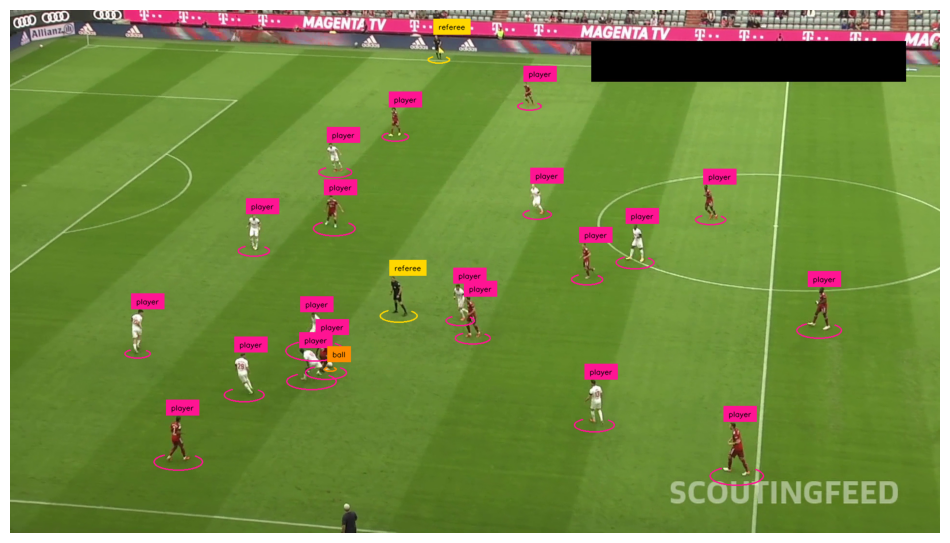

In [ ]:
from tqdm import tqdm
import supervision as sv

SOURCE_VIDEO_PATH = "/content/test_59.mp4"
TARGET_VIDEO_PATH = "/content/test_59_result_1.mp4"

elipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#FF8C00', '#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)

label_annotator = sv.LabelAnnotator(
    color=sv.ColorPalette.from_hex(['#FF8C00', '#00BFFF', '#FF1493', '#FFD700']),
    text_color=sv.Color.from_hex("#000000")
)

video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
video_sink = sv.VideoSink(TARGET_VIDEO_PATH, video_info=video_info)
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)

with video_sink:
    for frame in tqdm(frame_generator,total=video_info.total_frames):

      result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
      detections = sv.Detections.from_inference(result)

      annotated_frame = frame.copy()
      annotated_frame = elipse_annotator.annotate(annotated_frame, detections)
      annotated_frame = label_annotator.annotate(annotated_frame, detections)
      video_sink.write_frame(annotated_frame)
sv.plot_image(annotated_frame)




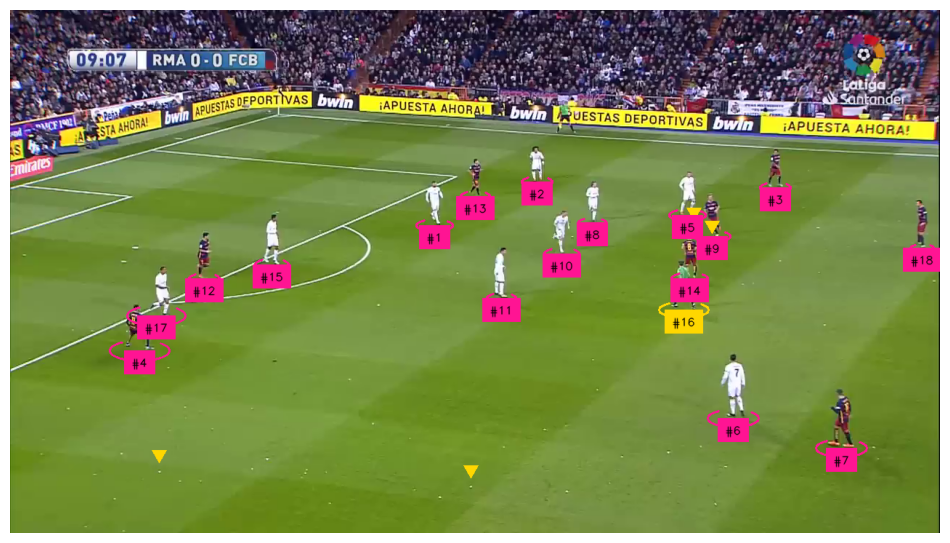

In [ ]:
import supervision as sv

SOURCE_VIDEO_PATH = "/content/RMAvsFCB_gol1.mp4"
BALL_ID = 0

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
     color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
     text_color=sv.Color.from_hex("#000000"),
     text_position=sv.Position.BOTTOM_CENTER
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.ColorPalette.from_hex(['#FFD700']),
    base=20, height=17
)

tracker = sv.ByteTrack()
tracker.reset()

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections.class_id = all_detections.class_id - 1
all_detections = tracker.update_with_detections(detections=all_detections)

labels = [
    f"#{tracker_id}"
    for tracker_id
    in all_detections.tracker_id
]

annotated_frame = frame.copy()
annotated_frame = ellipse_annotator.annotate(annotated_frame, all_detections)
annotated_frame = triangle_annotator.annotate(annotated_frame, ball_detections)
annotated_frame = label_annotator.annotate(annotated_frame, all_detections, labels=labels)

sv.plot_image(annotated_frame)


In [ ]:
from tqdm import tqdm

STRIDE = 30
PLAYER_ID = 2

def extract_crops(source_video_path: str):
    frame_generator = sv.get_video_frames_generator(source_video_path, stride=STRIDE)

    crops = []
    for frame in tqdm(frame_generator, desc='collecting crops'):
      result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
      detections = sv.Detections.from_inference(result)
      detections = detections.with_nms(threshold=0.5, class_agnostic=True)
      detections = detections[detections.class_id == PLAYER_ID]
      crops += [
          sv.crop_image(frame, xyxy)
          for xyxy
          in detections.xyxy
      ]
    return crops

In [ ]:
crops = extract_crops(SOURCE_VIDEO_PATH)

collecting crops: 48it [00:25,  1.91it/s]


In [ ]:
len(crops)

820

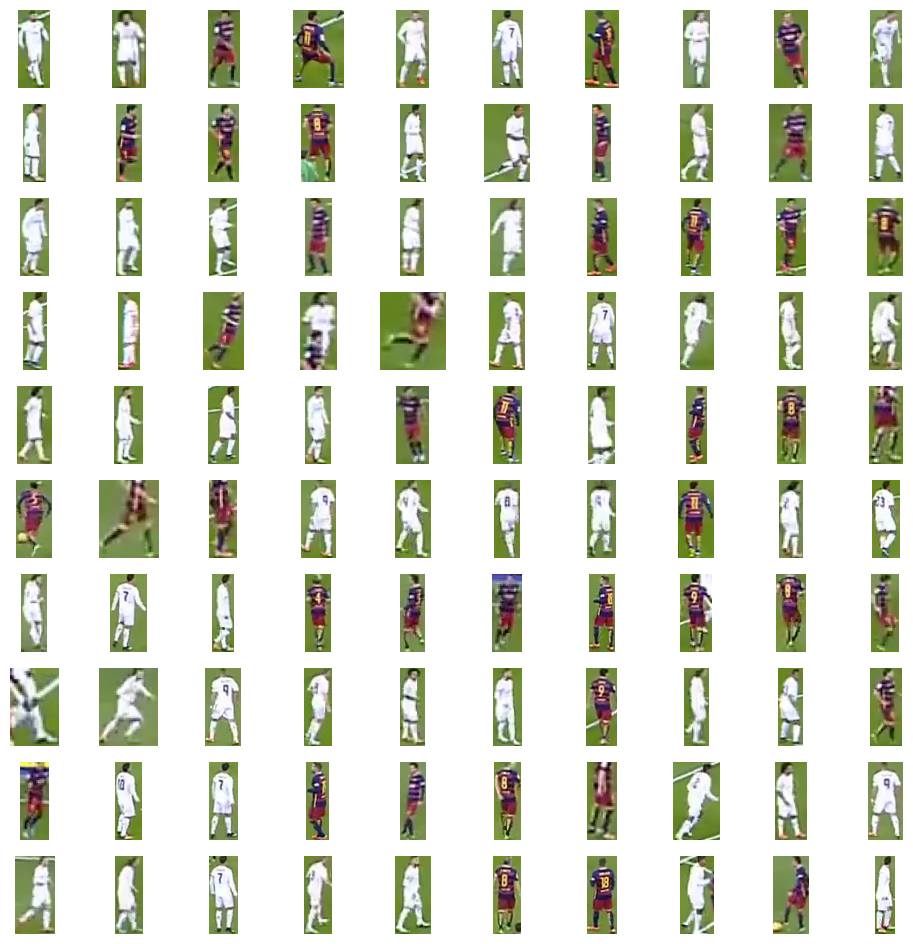

In [ ]:
sv.plot_images_grid(crops[:100], grid_size=(10,10))

In [ ]:
import torch
from transformers import AutoProcessor, SiglipVisionModel

SIGLIP_MODEL_PATH = 'google/siglip-base-patch16-224'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
EMBEDDINGS_MODEL = SiglipVisionModel.from_pretrained(SIGLIP_MODEL_PATH).to(DEVICE)
EMBEDDINGS_PROCESSOR = AutoProcessor.from_pretrained(SIGLIP_MODEL_PATH)

The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.


config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/813M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
import numpy as np
from more_itertools import chunked

BATCH_SIZE = 32

crops = [sv.cv2_to_pillow(crop) for crop in crops]
batches = chunked(crops, BATCH_SIZE)
data = []

with torch.no_grad():
  for batch in tqdm(batches, desc='embeddings extraction'):
    input = EMBEDDINGS_PROCESSOR(images=batch, return_tensors='pt').to(DEVICE)
    outputs = EMBEDDINGS_MODEL(**input)
    embeddings = torch.mean(outputs.last_hidden_state, dim=1).cpu().numpy()
    data.append(embeddings)


data = np.concatenate(data)

embeddings extraction: 26it [00:10,  2.50it/s]


In [ ]:
data.shape

(820, 768)

In [ ]:
import umap
from sklearn.cluster import KMeans

REDUCER = umap.UMAP(n_components=3)
CLUSTERING_MODEL = KMeans(n_clusters=2)

In [ ]:
projections = REDUCER.fit_transform(data)

In [ ]:
projections.shape

(820, 3)

In [ ]:
clusters = CLUSTERING_MODEL.fit_predict(projections)

In [ ]:
clusters[:10]

array([1, 1, 0, 0, 1, 1, 0, 1, 0, 1], dtype=int32)

In [ ]:
team_0 = [
    crop
    for crop, cluster
    in zip(crops, clusters)
    if cluster == 0
]

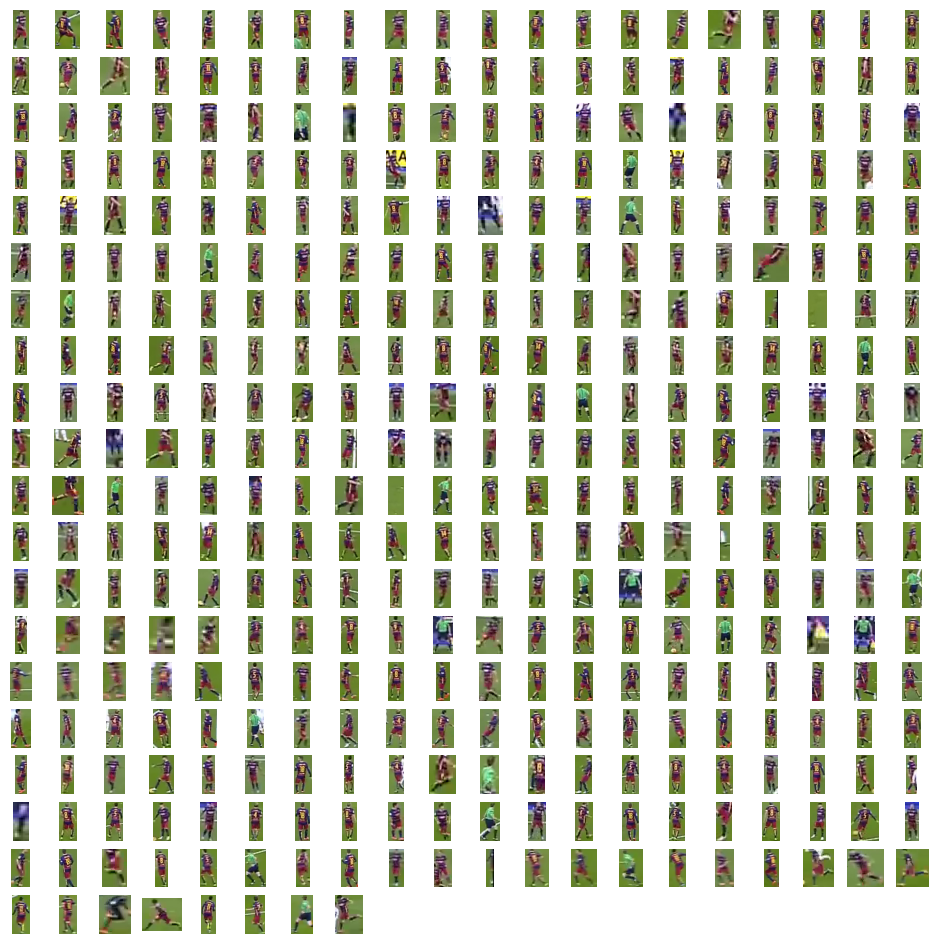

In [ ]:
sv.plot_images_grid(team_0, grid_size=(20,20))

## version 2 separa por equipos

collecting crops: 48it [00:21,  2.23it/s]
Embedding extraction: 26it [00:10,  2.49it/s]
Embedding extraction: 1it [00:00,  4.47it/s]


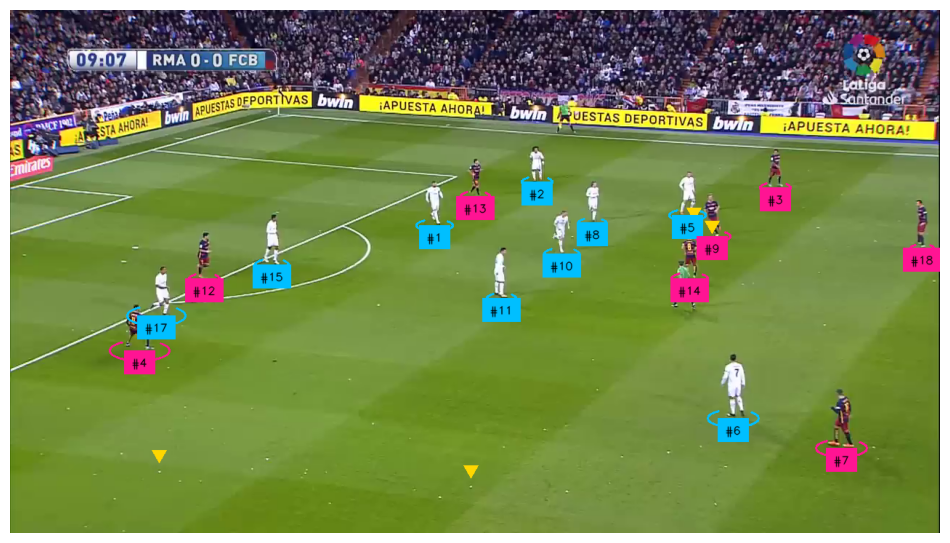

In [ ]:
import supervision as sv
from sports.common.team import TeamClassifier

SOURCE_VIDEO_PATH = "/content/RMAvsFCB_gol1.mp4"
BALL_ID = 0
PLAYER_ID = 2

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
     color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
     text_color=sv.Color.from_hex("#000000"),
     text_position=sv.Position.BOTTOM_CENTER
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.ColorPalette.from_hex(['#FFD700']),
    base=20, height=17
)

tracker = sv.ByteTrack()
tracker.reset()

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections = tracker.update_with_detections(detections=all_detections)

players_detections = all_detections[all_detections.class_id == PLAYER_ID]
players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
players_detections.class_id = team_classifier.predict(players_crops)

labels = [
    f"#{tracker_id}"
    for tracker_id
    in players_detections.tracker_id
]

annotated_frame = frame.copy()
annotated_frame = ellipse_annotator.annotate(annotated_frame, players_detections)
annotated_frame = triangle_annotator.annotate(annotated_frame, ball_detections)
annotated_frame = label_annotator.annotate(annotated_frame, players_detections, labels=labels)

sv.plot_image(annotated_frame)


## Version 3 separa por equipos, porteros y arbitros

In [ ]:
def resolve_goalkeepers_team_id(
    player_detections: sv.Detections,
    goalkeepers_detections: sv.Detections
):
    goalkeepers_xy = goalkeepers_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    players_xy = players_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)

    team_0_centroid = players_xy [players_detections.class_id == 0].mean(axis=0)
    team_1_centroid = players_xy [players_detections.class_id == 1].mean(axis=0)

    goalkeepers_team_ids = []
    for goalkeeper_xy in goalkeepers_xy:
        dist_0 = np.linalg.norm(goalkeeper_xy - team_0_centroid)
        dist_1 = np.linalg.norm(goalkeeper_xy - team_1_centroid)
        goalkeepers_team_ids.append(0 if dist_0 < dist_1 else 1)

    return np.array(goalkeepers_team_ids)

# Version 3 NO FUNCIONA

collecting crops: 6it [00:04,  1.43it/s]
Embedding extraction: 4it [00:01,  2.76it/s]
Embedding extraction: 1it [00:00,  4.38it/s]


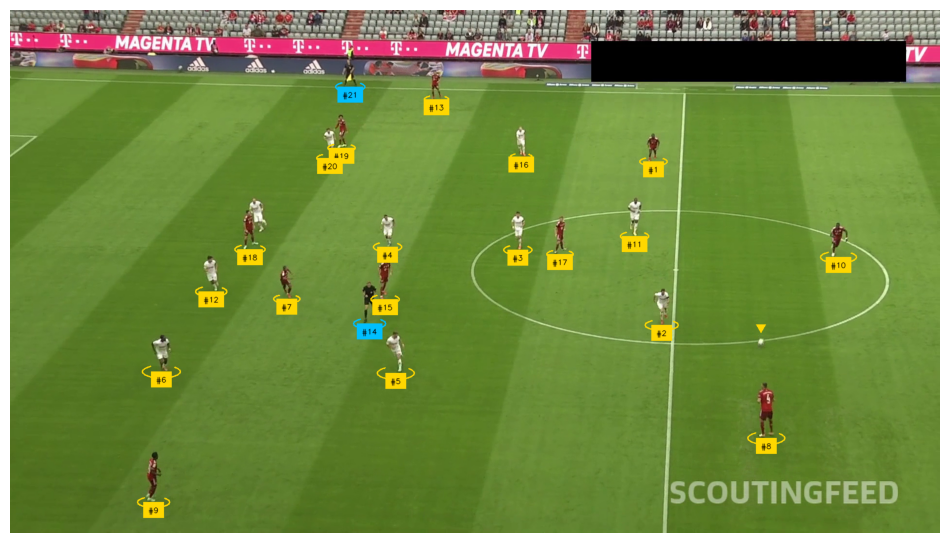

In [ ]:
import supervision as sv
from sports.common.team import TeamClassifier

SOURCE_VIDEO_PATH = "/content/test_59.mp4"
BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
     color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
     text_color=sv.Color.from_hex("#000000"),
     text_position=sv.Position.BOTTOM_CENTER
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.ColorPalette.from_hex(['#FFD700']),
    base=20, height=17
)

tracker = sv.ByteTrack()
tracker.reset()

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections = tracker.update_with_detections(detections=all_detections)

players_detections = all_detections[all_detections.class_id == PLAYER_ID]
goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
players_detections.class_id = team_classifier.predict(players_crops)

goalkeepers_detections.class_id = resolve_goalkeepers_team_id(
    players_detections, goalkeepers_detections
)

referees_detections.class_id -= 1

aa_detections = sv.Detections.merge([players_detections, goalkeepers_detections, referees_detections])

labels = [
    f"#{tracker_id}"
    for tracker_id
    in all_detections.tracker_id
]

annotated_frame = frame.copy()
annotated_frame = ellipse_annotator.annotate(annotated_frame, all_detections)
annotated_frame = triangle_annotator.annotate(annotated_frame, ball_detections)
annotated_frame = label_annotator.annotate(annotated_frame, all_detections, labels=labels)

sv.plot_image(annotated_frame)


collecting crops: 48it [00:17,  2.72it/s]
Embedding extraction: 26it [00:10,  2.46it/s]
Embedding extraction: 1it [00:00,  4.54it/s]


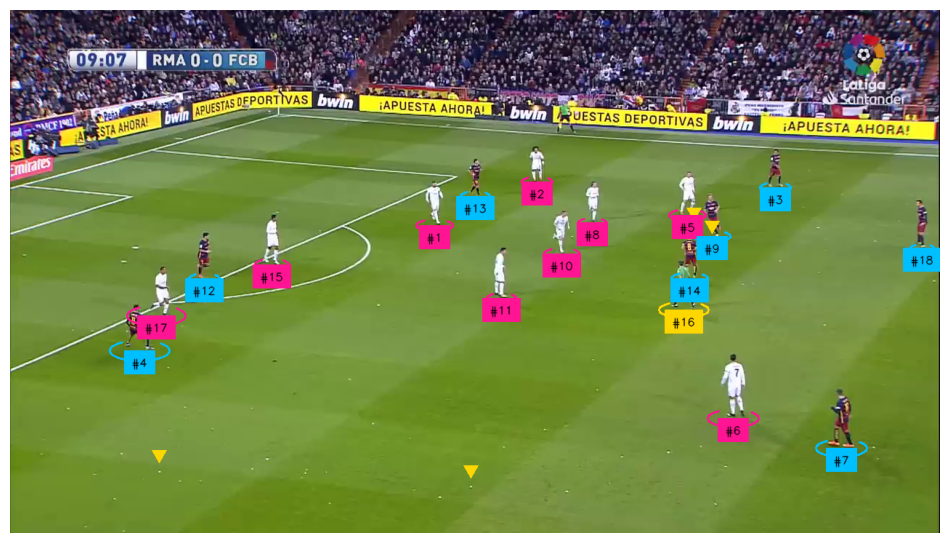

In [ ]:
import supervision as sv
from sports.common.team import TeamClassifier
import numpy as np

SOURCE_VIDEO_PATH = "/content/RMAvsFCB_gol1.mp4"
BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
     color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
     text_color=sv.Color.from_hex("#000000"),
     text_position=sv.Position.BOTTOM_CENTER
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.ColorPalette.from_hex(['#FFD700']),
    base=20, height=17
)

tracker = sv.ByteTrack()
tracker.reset()

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections = tracker.update_with_detections(detections=all_detections)

players_detections = all_detections[all_detections.class_id == PLAYER_ID]
goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
players_detections.class_id = team_classifier.predict(players_crops)

def resolve_goalkeepers_team_id(players_detections, goalkeepers_detections):
    if len(players_detections) == 0 or len(goalkeepers_detections) == 0:
        return goalkeepers_detections.class_id
    new_class_ids = []
    for goalkeeper_xyxy in goalkeepers_detections.xyxy:
        distances = np.linalg.norm(
            players_detections.xyxy[:, :2] - goalkeeper_xyxy[:2], axis=1
        )
        closest_player_idx = np.argmin(distances)
        new_class_ids.append(players_detections.class_id[closest_player_idx])
    return np.array(new_class_ids)

if len(goalkeepers_detections) > 0:
    goalkeepers_detections.class_id = resolve_goalkeepers_team_id(players_detections, goalkeepers_detections)

if len(referees_detections) > 0:
    referees_detections.class_id = np.full(len(referees_detections), 2)

aa_detections = sv.Detections.merge([players_detections, goalkeepers_detections, referees_detections])

labels = [f"#{tracker_id}" for tracker_id in aa_detections.tracker_id]

annotated_frame = frame.copy()
annotated_frame = ellipse_annotator.annotate(annotated_frame, aa_detections)
annotated_frame = triangle_annotator.annotate(annotated_frame, ball_detections)
annotated_frame = label_annotator.annotate(annotated_frame, aa_detections, labels=labels)

sv.plot_image(annotated_frame)

## Descarga de la version 3


In [ ]:
from tqdm import tqdm
import supervision as sv
from sports.common.team import TeamClassifier
import numpy as np

SOURCE_VIDEO_PATH = "/content/RMAvsFCB_gol1.mp4"
TARGET_VIDEO_PATH = "/content/custom_result.mp4"
BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
#label_annotator = sv.LabelAnnotator(
#     color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
#     text_color=sv.Color.from_hex("#000000"),
#     text_position=sv.Position.BOTTOM_CENTER
#)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.ColorPalette.from_hex(['#FFD700']),
    base=20, height=17
)

tracker = sv.ByteTrack()
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
video_sink = sv.VideoSink(TARGET_VIDEO_PATH, video_info=video_info)
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)

with video_sink:
    for frame in tqdm(frame_generator, total=video_info.total_frames):
        tracker.reset()
        result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
        detections = sv.Detections.from_inference(result)

        ball_detections = detections[detections.class_id == BALL_ID]
        ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

        all_detections = detections[detections.class_id != BALL_ID]
        all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
        all_detections = tracker.update_with_detections(detections=all_detections)

        players_detections = all_detections[all_detections.class_id == PLAYER_ID]
        goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
        referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

        if len(players_detections) > 0:
            players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
            players_detections.class_id = team_classifier.predict(players_crops)

        def resolve_goalkeepers_team_id(players_detections, goalkeepers_detections):
            if len(players_detections) == 0 or len(goalkeepers_detections) == 0:
                return goalkeepers_detections.class_id
            new_class_ids = []
            for goalkeeper_xyxy in goalkeepers_detections.xyxy:
                distances = np.linalg.norm(
                    players_detections.xyxy[:, :2] - goalkeeper_xyxy[:2], axis=1
                )
                closest_player_idx = np.argmin(distances)
                new_class_ids.append(players_detections.class_id[closest_player_idx])
            return np.array(new_class_ids)

        if len(goalkeepers_detections) > 0:
            goalkeepers_detections.class_id = resolve_goalkeepers_team_id(players_detections, goalkeepers_detections)

        if len(referees_detections) > 0:
            referees_detections.class_id = np.full(len(referees_detections), 2)

        aa_detections = sv.Detections.merge([players_detections, goalkeepers_detections, referees_detections])

        labels = [f"#{tracker_id}" for tracker_id in aa_detections.tracker_id]

        annotated_frame = frame.copy()
        annotated_frame = ellipse_annotator.annotate(annotated_frame, aa_detections)
        annotated_frame = triangle_annotator.annotate(annotated_frame, ball_detections)
        annotated_frame = label_annotator.annotate(annotated_frame, aa_detections, labels=labels)

        video_sink.write_frame(annotated_frame)

collecting crops: 48it [00:20,  2.33it/s]
Embedding extraction: 26it [00:11,  2.32it/s]
  0%|          | 0/1440 [00:00<?, ?it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.25it/s]
  0%|          | 1/1440 [00:00<13:53,  1.73it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.17it/s]
  0%|          | 2/1440 [00:01<13:44,  1.74it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.02it/s]
  0%|          | 3/1440 [00:01<13:49,  1.73it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.19it/s]
  0%|          | 4/1440 [00:02<13:43,  1.74it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.20it/s]
  0%|          | 5/1440 [00:02<13:38,  1.75it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.16it/s]
  0%|          | 6/1440 [00:03<13:37,  1.75it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction

## Keypoint detections

In [ ]:
PITCH_DETECTION_MODEL_ID = "football-field-detection-f07vi/14"
PITCH_DETECTION_MODEL = get_model(PITCH_DETECTION_MODEL_ID, ROBOFLOW_API_KEY)

Resolved model_id: football-field-detection-f07vi/14, dataset_id: football-field-detection-f07vi, version_id: 14


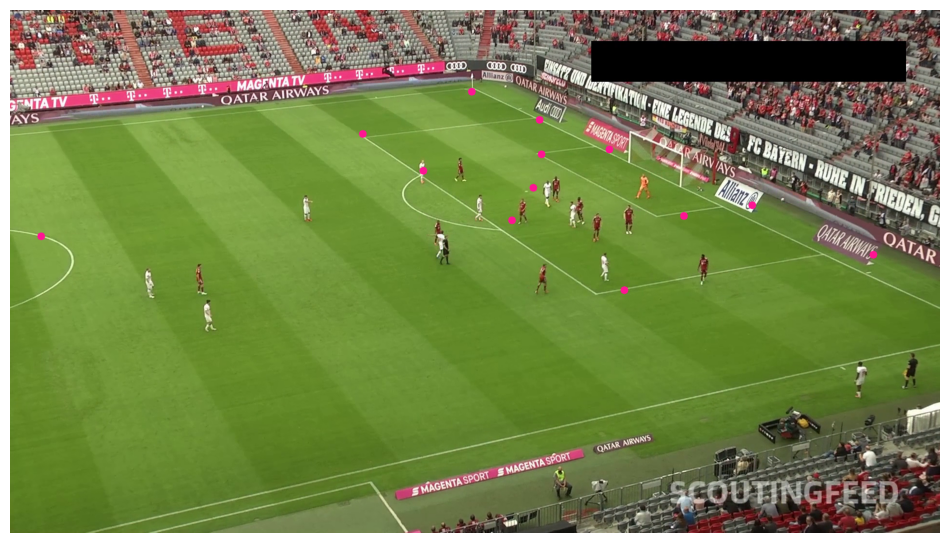

In [ ]:
vertex_annotator = sv.VertexAnnotator(
    color=sv.Color.from_hex("#FF1493"),
    radius=8
)

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PITCH_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
key_points = sv.KeyPoints.from_inference(result)

filter = key_points.confidence[0] > 0.5
frame_reference_points = key_points.xy[0][filter]
frame_reference_key_points = sv.KeyPoints(xy=frame_reference_points[np.newaxis, ...])

annotated_frame = frame.copy()
annotated_frame = vertex_annotator.annotate(annotated_frame, frame_reference_key_points)

sv.plot_image(annotated_frame)

## porject pitch lines on frame

In [ ]:
from sports.configs.soccer import SoccerPitchConfiguration

CONFIG = SoccerPitchConfiguration()

In [ ]:
CONFIG.vertices

[(0, 0),
 (0, 1450.0),
 (0, 2584.0),
 (0, 4416.0),
 (0, 5550.0),
 (0, 7000),
 (550, 2584.0),
 (550, 4416.0),
 (1100, 3500.0),
 (2015, 1450.0),
 (2015, 2584.0),
 (2015, 4416.0),
 (2015, 5550.0),
 (6000.0, 0),
 (6000.0, 2585.0),
 (6000.0, 4415.0),
 (6000.0, 7000),
 (9985, 1450.0),
 (9985, 2584.0),
 (9985, 4416.0),
 (9985, 5550.0),
 (10900, 3500.0),
 (11450, 2584.0),
 (11450, 4416.0),
 (12000, 0),
 (12000, 1450.0),
 (12000, 2584.0),
 (12000, 4416.0),
 (12000, 5550.0),
 (12000, 7000),
 (5085.0, 3500.0),
 (6915.0, 3500.0)]

In [ ]:
CONFIG.edges

[(1, 2),
 (2, 3),
 (3, 4),
 (4, 5),
 (5, 6),
 (7, 8),
 (10, 11),
 (11, 12),
 (12, 13),
 (14, 15),
 (15, 16),
 (16, 17),
 (18, 19),
 (19, 20),
 (20, 21),
 (23, 24),
 (25, 26),
 (26, 27),
 (27, 28),
 (28, 29),
 (29, 30),
 (1, 14),
 (2, 10),
 (3, 7),
 (4, 8),
 (5, 13),
 (6, 17),
 (14, 25),
 (18, 26),
 (23, 27),
 (24, 28),
 (21, 29),
 (17, 30)]

In [ ]:
import cv2

class ViewTransformer:
    def __init__(self, source: np.ndarray, target: np.ndarray):
        source = source.astype(np.float32)
        target = target.astype(np.float32)
        self.m, _ = cv2.findHomography(source, target)

    def transform_points(self, points: np.ndarray) -> np.ndarray:
        if self.m is None or points is None or len(points) == 0:
            return None
        points = points.reshape(-1, 1, 2).astype(np.float32)
        points = cv2.perspectiveTransform(points, self.m)
        if points is None:
            return None
        return points.reshape(-1, 2).astype(np.float32)

## Minimapa estilo fifa

collecting crops: 6it [00:03,  1.85it/s]
Embedding extraction: 4it [00:01,  2.63it/s]
Embedding extraction: 1it [00:00,  4.12it/s]


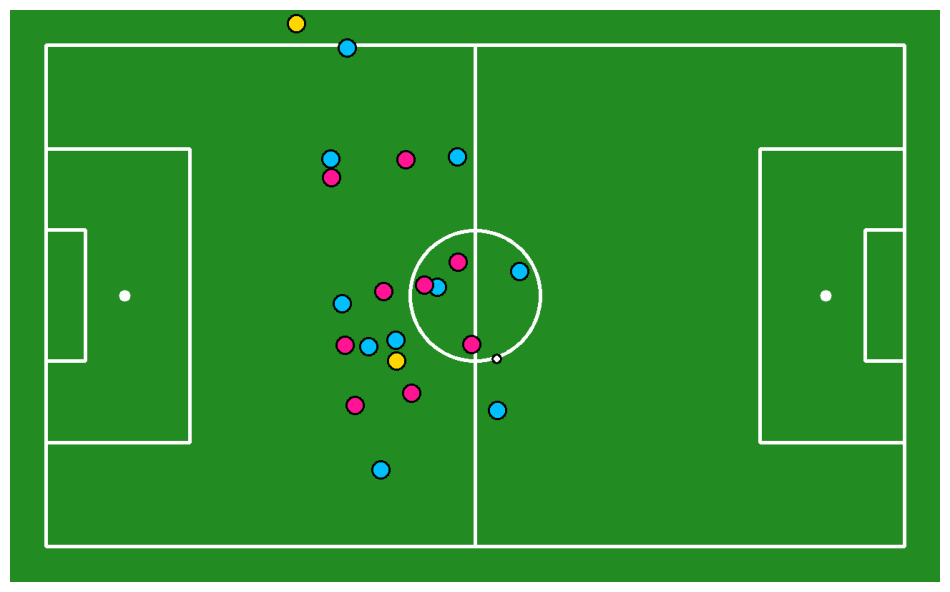

In [ ]:
import cv2
import numpy as np
import supervision as sv
from sports.common.team import TeamClassifier
from sports.annotators.soccer import draw_pitch, draw_points_on_pitch

class ViewTransformer:
    def __init__(self, source: np.ndarray, target: np.ndarray):
        source = source.astype(np.float32)
        target = target.astype(np.float32)
        self.m, _ = cv2.findHomography(source, target)

    def transform_points(self, points: np.ndarray) -> np.ndarray:
        if self.m is None or points is None or len(points) == 0:
            return None
        points = points.reshape(-1, 1, 2).astype(np.float32)
        points = cv2.perspectiveTransform(points, self.m)
        if points is None:
            return None
        return points.reshape(-1, 2).astype(np.float32)


SOURCE_VIDEO_PATH = "/content/test_59.mp4"
BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

tracker = sv.ByteTrack()
tracker.reset()

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections = tracker.update_with_detections(detections=all_detections)

players_detections = all_detections[all_detections.class_id == PLAYER_ID]
goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
players_detections.class_id = team_classifier.predict(players_crops)

def resolve_goalkeepers_team_id(players_detections, goalkeepers_detections):
    if len(players_detections) == 0 or len(goalkeepers_detections) == 0:
        return goalkeepers_detections.class_id
    new_class_ids = []
    for goalkeeper_xyxy in goalkeepers_detections.xyxy:
        distances = np.linalg.norm(
            players_detections.xyxy[:, :2] - goalkeeper_xyxy[:2], axis=1
        )
        closest_player_idx = np.argmin(distances)
        new_class_ids.append(players_detections.class_id[closest_player_idx])
    return np.array(new_class_ids)

if len(goalkeepers_detections) > 0:
    goalkeepers_detections.class_id = resolve_goalkeepers_team_id(
        players_detections, goalkeepers_detections
    )

if len(referees_detections) > 0:
    referees_detections.class_id = np.full(len(referees_detections), 2)

result = PITCH_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
key_points = sv.KeyPoints.from_inference(result)

mask = key_points.confidence[0] > 0.5
frame_reference_points = key_points.xy[0][mask]
pitch_reference_points = np.array(CONFIG.vertices)[mask]

pitch = draw_pitch(config=CONFIG)

if len(frame_reference_points) >= 4:
    view_transformer = ViewTransformer(
        source=frame_reference_points,
        target=pitch_reference_points
    )

    frame_ball_xy = ball_detections.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )
    frame_players_xy = players_detections.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )
    frame_goalkeepers_xy = goalkeepers_detections.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )
    frame_referees_xy = referees_detections.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )

    pitch_ball_xy = view_transformer.transform_points(frame_ball_xy)
    pitch_players_xy = view_transformer.transform_points(frame_players_xy)
    pitch_goalkeepers_xy = view_transformer.transform_points(frame_goalkeepers_xy)
    pitch_referees_xy = view_transformer.transform_points(frame_referees_xy)

    if pitch_players_xy is not None:
        pitch = draw_points_on_pitch(
            config=CONFIG,
            xy=pitch_players_xy[players_detections.class_id == 0],
            face_color=sv.Color.from_hex("#00BFFF"),
            edge_color=sv.Color.BLACK,
            radius=12,
            pitch=pitch
        )
        pitch = draw_points_on_pitch(
            config=CONFIG,
            xy=pitch_players_xy[players_detections.class_id == 1],
            face_color=sv.Color.from_hex("#FF1493"),
            edge_color=sv.Color.BLACK,
            radius=12,
            pitch=pitch
        )

    if pitch_goalkeepers_xy is not None:
        pitch = draw_points_on_pitch(
            config=CONFIG,
            xy=pitch_goalkeepers_xy,
            face_color=sv.Color.from_hex("#00BFFF"),
            edge_color=sv.Color.BLACK,
            radius=12,
            pitch=pitch
        )

    if pitch_referees_xy is not None:
        pitch = draw_points_on_pitch(
            config=CONFIG,
            xy=pitch_referees_xy,
            face_color=sv.Color.from_hex("#FFD700"),
            edge_color=sv.Color.BLACK,
            radius=12,
            pitch=pitch
        )

    if pitch_ball_xy is not None:
        pitch = draw_points_on_pitch(
            config=CONFIG,
            xy=pitch_ball_xy,
            face_color=sv.Color.WHITE,
            edge_color=sv.Color.BLACK,
            radius=6,
            pitch=pitch
        )

sv.plot_image(pitch)

In [ ]:
!apt update && apt install -y libx264-dev

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [83.8 kB]
Get:9 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,309 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Get:11 https://cli.github.com/packages stable/main amd64 Packages [356 B]
Get:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease [24.3 kB]
Get:13 http://archive.ubuntu.com/ubu

# DESCARGA DEL VIDEO CON MINIMAPA

In [ ]:
import cv2
import numpy as np
import supervision as sv
from tqdm import tqdm
from sports.common.team import TeamClassifier
from sports.annotators.soccer import draw_pitch, draw_points_on_pitch
import os

class ViewTransformer:
    def __init__(self, source: np.ndarray, target: np.ndarray):
        source = source.astype(np.float32)
        target = target.astype(np.float32)
        self.m, _ = cv2.findHomography(source, target, cv2.RANSAC, 5.0)

    def transform_points(self, points: np.ndarray) -> np.ndarray:
        if self.m is None:
            return None
        if points is None or len(points) == 0:
            return None
        points = points.reshape(-1, 1, 2).astype(np.float32)
        transformed = cv2.perspectiveTransform(points, self.m)
        return transformed.reshape(-1, 2).astype(np.float32)

SOURCE_VIDEO_PATH = "/content/test_59.mp4"
OUTPUT_VIDEO_PATH = "/content/minimap_output.mp4"

BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

assert os.path.exists(SOURCE_VIDEO_PATH), f"Video de entrada no encontrado: {SOURCE_VIDEO_PATH}"

video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)

crops = extract_crops(SOURCE_VIDEO_PATH)
team_classifier = TeamClassifier(device=DEVICE)
team_classifier.fit(crops)

tracker = sv.ByteTrack()

pitch_sample = draw_pitch(config=CONFIG)
height, width = pitch_sample.shape[:2]
video_info_out = sv.VideoInfo(
    width=width,
    height=height,
    fps=video_info.fps,
    total_frames=video_info.total_frames
)

with sv.VideoSink(
    target_path=OUTPUT_VIDEO_PATH,
    video_info=video_info_out,
    codec="mp4v"
) as sink:
    frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
    frame_count = 0
    keypoints_counts = []
    error_count = 0

    for frame in tqdm(frame_generator, total=video_info.total_frames):
        try:
            frame_count += 1
            tracker.reset()

            result = PLAYER_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
            detections = sv.Detections.from_inference(result)

            ball_detections = detections[detections.class_id == BALL_ID]
            ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

            all_detections = detections[detections.class_id != BALL_ID]
            all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
            all_detections = tracker.update_with_detections(detections=all_detections)

            players_detections = all_detections[all_detections.class_id == PLAYER_ID]
            goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
            referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

            if len(players_detections) > 0:
                players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
                players_detections.class_id = team_classifier.predict(players_crops)

            def resolve_goalkeepers_team_id(players_detections, goalkeepers_detections):
                if len(players_detections) == 0 or len(goalkeepers_detections) == 0:
                    return goalkeepers_detections.class_id
                new_class_ids = []
                for goalkeeper_xyxy in goalkeepers_detections.xyxy:
                    distances = np.linalg.norm(
                        players_detections.xyxy[:, :2] - goalkeeper_xyxy[:2], axis=1
                    )
                    closest_player_idx = np.argmin(distances)
                    new_class_ids.append(players_detections.class_id[closest_player_idx])
                return np.array(new_class_ids)

            if len(goalkeepers_detections) > 0:
                goalkeepers_detections.class_id = resolve_goalkeepers_team_id(
                    players_detections, goalkeepers_detections
                )

            if len(referees_detections) > 0:
                referees_detections.class_id = np.full(len(referees_detections), 2)

            result = PITCH_DETECTION_MODEL.infer(frame, confidence=0.3)[0]
            key_points = sv.KeyPoints.from_inference(result)

            mask = key_points.confidence[0] > 0.2
            frame_reference_points = key_points.xy[0][mask]
            pitch_reference_points = np.array(CONFIG.vertices)[mask]

            keypoints_counts.append(len(frame_reference_points))

            pitch = draw_pitch(config=CONFIG)

            if len(frame_reference_points) >= 4:
                view_transformer = ViewTransformer(
                    source=frame_reference_points,
                    target=pitch_reference_points
                )

                frame_ball_xy = ball_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
                frame_players_xy = players_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
                frame_goalkeepers_xy = goalkeepers_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
                frame_referees_xy = referees_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)

                pitch_ball_xy = view_transformer.transform_points(frame_ball_xy)
                pitch_players_xy = view_transformer.transform_points(frame_players_xy)
                pitch_goalkeepers_xy = view_transformer.transform_points(frame_goalkeepers_xy)
                pitch_referees_xy = view_transformer.transform_points(frame_referees_xy)

                if pitch_players_xy is not None and len(pitch_players_xy) > 0:
                    team_0_mask = players_detections.class_id == 0
                    team_1_mask = players_detections.class_id == 1

                    if np.any(team_0_mask):
                        pitch = draw_points_on_pitch(
                            config=CONFIG,
                            xy=pitch_players_xy[team_0_mask],
                            face_color=sv.Color.from_hex("#00BFFF"),
                            edge_color=sv.Color.BLACK,
                            radius=12,
                            pitch=pitch
                        )

                    if np.any(team_1_mask):
                        pitch = draw_points_on_pitch(
                            config=CONFIG,
                            xy=pitch_players_xy[team_1_mask],
                            face_color=sv.Color.from_hex("#FF1493"),
                            edge_color=sv.Color.BLACK,
                            radius=12,
                            pitch=pitch
                        )

                if pitch_goalkeepers_xy is not None and len(pitch_goalkeepers_xy) > 0:
                    pitch = draw_points_on_pitch(
                        config=CONFIG,
                        xy=pitch_goalkeepers_xy,
                        face_color=sv.Color.from_hex("#00BFFF"),
                        edge_color=sv.Color.BLACK,
                        radius=12,
                        pitch=pitch
                    )

                if pitch_referees_xy is not None and len(pitch_referees_xy) > 0:
                    pitch = draw_points_on_pitch(
                        config=CONFIG,
                        xy=pitch_referees_xy,
                        face_color=sv.Color.from_hex("#FFD700"),
                        edge_color=sv.Color.BLACK,
                        radius=12,
                        pitch=pitch
                    )

                if pitch_ball_xy is not None and len(pitch_ball_xy) > 0:
                    pitch = draw_points_on_pitch(
                        config=CONFIG,
                        xy=pitch_ball_xy,
                        face_color=sv.Color.WHITE,
                        edge_color=sv.Color.BLACK,
                        radius=6,
                        pitch=pitch
                    )

            sink.write_frame(pitch)

        except Exception as e:
            error_count += 1
            pitch = draw_pitch(config=CONFIG)
            sink.write_frame(pitch)

print(f"Total frames procesados: {frame_count}")
print(f"Keypoints promedio por frame: {np.mean(keypoints_counts):.1f}")
print(f"Errores en frames: {error_count}")

if os.path.exists(OUTPUT_VIDEO_PATH):
    print(f"✅ Video guardado en: {OUTPUT_VIDEO_PATH}")
else:
    print("❌ ERROR: El archivo de salida NO se generó.")

collecting crops: 6it [00:03,  1.86it/s]
Embedding extraction: 4it [00:01,  2.84it/s]
  0%|          | 0/327 [00:00<?, ?it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.30it/s]
  0%|          | 1/327 [00:01<08:15,  1.52s/it]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  3.96it/s]
  1%|          | 2/327 [00:02<05:25,  1.00s/it]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  4.00it/s]
  1%|          | 3/327 [00:02<04:34,  1.18it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  3.88it/s]
  1%|          | 4/327 [00:03<04:10,  1.29it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  3.81it/s]
  2%|▏         | 5/327 [00:04<03:56,  1.36it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00:00,  3.85it/s]
  2%|▏         | 6/327 [00:04<03:51,  1.39it/s]
Embedding extraction: 0it [00:00, ?it/s]
Embedding extraction: 1it [00

Total frames procesados: 151
Keypoints promedio por frame: 8.3
Errores en frames: 0
✅ Video guardado en: /content/minimap_output.mp4


In [ ]:
# 2. ¿Cuántos frames tiene el vídeo ORIGINAL?
!ffprobe -v error -select_streams v:0 -count_packets \
    -show_entries stream=nb_read_packets \
    -of csv=p=0 /content/test_119.mp4


477
